**Nombre completo: JESUS MANUEL NORIEGA VELAZQUEZ**

**Grupo: 002**

**Fecha: 21/10/2026**

---

# Soluciones · Actividades 11 y 12 · Eventos discretos y continuos

Simulación de Sistemas. La primera celda repite la función `simular` de la Parte A para que este notebook corra solo; si copias las celdas al tuyo, no la repitas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def simular(llegadas, servicios):
    reloj = 0.0
    eventos = [(llegadas[0], 1, "llegada", 0)]
    cola = []
    en_ventanilla = None
    atendidos = 0
    espera_total = 0.0
    tiempo_ocupado = 0.0
    registro = []

    def atender(cliente):
        nonlocal en_ventanilla, tiempo_ocupado
        en_ventanilla = cliente
        eventos.append((reloj + servicios[cliente], 0, "salida", cliente))
        tiempo_ocupado += servicios[cliente]

    while eventos:
        eventos.sort()
        reloj, _, tipo, cliente = eventos.pop(0)

        if tipo == "llegada":
            if cliente + 1 < len(llegadas):
                eventos.append((llegadas[cliente + 1], 1, "llegada", cliente + 1))
            if en_ventanilla is None:
                atender(cliente)
            else:
                cola.append(cliente)
        else:  # salida
            atendidos += 1
            en_ventanilla = None
            if cola:
                siguiente = cola.pop(0)
                espera_total += reloj - llegadas[siguiente]
                atender(siguiente)

        registro.append({"reloj": reloj, "evento": f"{tipo} C{cliente + 1}",
                         "cola": len(cola), "atendidos": atendidos,
                         "espera_total": espera_total})

    contadores = {"atendidos": atendidos,
                  "espera_promedio": espera_total / atendidos,
                  "ocupacion": tiempo_ocupado / reloj}
    return pd.DataFrame(registro), contadores

# Parte B · Actividad 11

## Ejercicio 1. Tabla de simulación a mano

Datos: C1 (llega 1, servicio 3), C2 (3, 2), C3 (4, 3), C4 (8, 1), C5 (9, 3), C6 (12, 2). En la columna *lista de eventos*, `L` = llegada y `S` = salida, con `@minuto`.

| Reloj | Evento | Cola | Ventanilla | Lista de eventos | Atendidos | Espera total |
|---|---|---|---|---|---|---|
| 1 | llegada C1 | — | C1 | LC2@3, SC1@4 | 0 | 0 |
| 3 | llegada C2 | C2 | C1 | SC1@4, LC3@4 | 0 | 0 |
| 4 | salida C1 | — | C2 | LC3@4, SC2@6 | 1 | 1 |
| 4 | llegada C3 | C3 | C2 | SC2@6, LC4@8 | 1 | 1 |
| 6 | salida C2 | — | C3 | LC4@8, SC3@9 | 2 | 3 |
| 8 | llegada C4 | C4 | C3 | SC3@9, LC5@9 | 2 | 3 |
| 9 | salida C3 | — | C4 | LC5@9, SC4@10 | 3 | 4 |
| 9 | llegada C5 | C5 | C4 | SC4@10, LC6@12 | 3 | 4 |
| 10 | salida C4 | — | C5 | LC6@12, SC5@13 | 4 | 5 |
| 12 | llegada C6 | C6 | C5 | SC5@13 | 4 | 5 |
| 13 | salida C5 | — | C6 | SC6@15 | 5 | 6 |
| 15 | salida C6 | — | libre | — | 6 | 6 |

**Empates.** Ocurren en los minutos **4** (salida de C1 y llegada de C3) y **9** (salida de C3 y llegada de C5). Los resolví atendiendo primero la salida: la ventanilla se libera y entra a servicio el primero de la cola, y después la llegada se forma en la cola. Por eso en esos minutos hay dos renglones con el mismo reloj, la salida primero.

**Contadores finales.**
- Clientes atendidos: **6**
- Espera promedio: 6 min de espera total / 6 clientes = **1.0 min** (C2 esperó 1, C3 esperó 2, C4, C5 y C6 esperaron 1 cada uno, C1 no esperó)
- Tiempo ocupado: 3 + 2 + 3 + 1 + 3 + 2 = 14 min de servicio, sobre 15 min de reloj, o sea **93.3 %**

## Ejercicio 2. Validar el algoritmo

La tabla que regresa `simular` tiene los mismos 12 renglones de mi tabla a mano (mismo reloj, evento, cola, atendidos y espera total).

In [3]:
llegadas_e1 = [1, 3, 4, 8, 9, 12]
servicios_e1 = [3, 2, 3, 1, 3, 2]

tabla_e1, cont_e1 = simular(llegadas_e1, servicios_e1)
display(tabla_e1)
print(cont_e1)

# Valores calculados a mano en el ejercicio 1
assert cont_e1["atendidos"] == 6
assert cont_e1["espera_promedio"] == 1.0          # 6 min de espera total / 6 clientes
assert abs(cont_e1["ocupacion"] - 14 / 15) < 1e-12  # 14 min ocupada / 15 min de reloj
print("Coincide con el cálculo a mano")

,reloj,evento,cola,atendidos,espera_total
0,1,llegada C1,0,0,0.0
1,3,llegada C2,1,0,0.0
2,4,salida C1,0,1,1.0
3,4,llegada C3,1,1,1.0
4,6,salida C2,0,2,3.0
5,8,llegada C4,1,2,3.0
6,9,salida C3,0,3,4.0
7,9,llegada C5,1,3,4.0
8,10,salida C4,0,4,5.0
9,12,llegada C6,1,4,5.0


{'atendidos': 6, 'espera_promedio': 1.0, 'ocupacion': 0.9333333333333333}
Coincide con el cálculo a mano


## Ejercicio 3. Simulación con tiempos aleatorios

Espera promedio:  3.473 min
Tiempo ocupado:   85.0 %
Cola máxima:      4 clientes


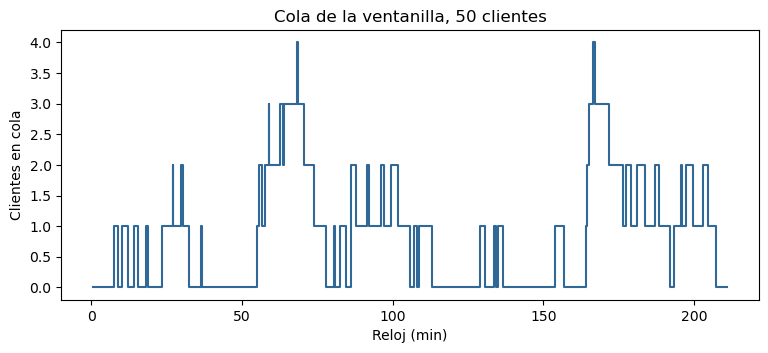

In [5]:
rng = np.random.default_rng(2026)
n = 50
llegadas = np.cumsum(rng.exponential(scale=4, size=n))
servicios = rng.uniform(2, 5, size=n)

tabla, cont = simular(llegadas, servicios)
print(f"Espera promedio:  {cont['espera_promedio']:.3f} min")
print(f"Tiempo ocupado:   {cont['ocupacion'] * 100:.1f} %")
print(f"Cola máxima:      {tabla['cola'].max()} clientes")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(tabla["reloj"], tabla["cola"], drawstyle="steps-post", color="#306998")
ax.set_xlabel("Reloj (min)")
ax.set_ylabel("Clientes en cola")
ax.set_title("Cola de la ventanilla, 50 clientes")
plt.show()

**Respuesta:** La cola solo cambia en el instante de una llegada (sube uno) o de una salida (baja uno), y entre un evento y el siguiente se queda igual. Por eso la gráfica va en escalones: el valor se mantiene constante hasta el siguiente evento, y unir los puntos con diagonales mostraría cambios graduales que no existen.

## Ejercicio 4. Contadores nuevos

In [7]:
def simular_con_contadores(llegadas, servicios):
    """Igual que simular, pero con dos contadores nuevos:
    tiempo en el sistema por cliente y clientes que esperaron más de 5 min."""
    reloj = 0.0
    eventos = [(llegadas[0], 1, "llegada", 0)]
    cola = []
    en_ventanilla = None
    atendidos = 0
    espera_total = 0.0
    tiempo_sistema_total = 0.0     # NUEVO contador 1
    esperaron_mas_de_5 = 0         # NUEVO contador 2

    def atender(cliente):
        nonlocal en_ventanilla, tiempo_sistema_total, esperaron_mas_de_5
        en_ventanilla = cliente
        eventos.append((reloj + servicios[cliente], 0, "salida", cliente))
        espera = reloj - llegadas[cliente]            # aquí ya se conoce la espera
        tiempo_sistema_total += espera + servicios[cliente]
        if espera > 5:
            esperaron_mas_de_5 += 1

    while eventos:
        eventos.sort()
        reloj, _, tipo, cliente = eventos.pop(0)
        if tipo == "llegada":
            if cliente + 1 < len(llegadas):
                eventos.append((llegadas[cliente + 1], 1, "llegada", cliente + 1))
            if en_ventanilla is None:
                atender(cliente)
            else:
                cola.append(cliente)
        else:
            atendidos += 1
            en_ventanilla = None
            if cola:
                siguiente = cola.pop(0)
                espera_total += reloj - llegadas[siguiente]
                atender(siguiente)

    return {"atendidos": atendidos,
            "espera_promedio": espera_total / atendidos,
            "tiempo_sistema_promedio": tiempo_sistema_total / atendidos,
            "esperaron_mas_de_5": esperaron_mas_de_5}

# Los mismos 50 clientes del ejercicio 3 (variables llegadas y servicios)
res = simular_con_contadores(llegadas, servicios)
print(f"Tiempo promedio en el sistema: {res['tiempo_sistema_promedio']:.3f} min")
print(f"Clientes que esperaron más de 5 min: {res['esperaron_mas_de_5']} de {res['atendidos']}")
print(f"(control) espera promedio: {res['espera_promedio']:.3f} min = la del ejercicio 3")
assert abs(res["espera_promedio"] - cont["espera_promedio"]) < 1e-9

Tiempo promedio en el sistema: 7.059 min
Clientes que esperaron más de 5 min: 16 de 50
(control) espera promedio: 3.473 min = la del ejercicio 3


**Respuesta:** Los dos contadores se actualizan en el momento en que un cliente **empieza a ser atendido** (dentro de `atender`), porque es cuando ya se conoce su espera (`reloj - llegada`). El tiempo en el sistema suma esa espera más su servicio, y el contador de más de 5 minutos suma uno cada vez que la espera supera 5.

## Ejercicio 5. La misma fila como modelo continuo

Nivel final de la fila (min 120): 3.300 clientes


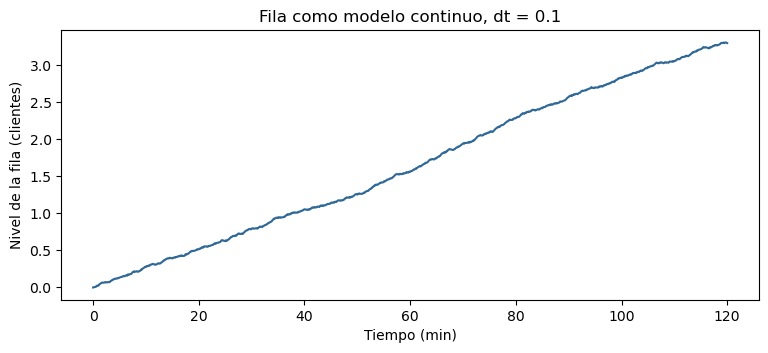

In [9]:
rng = np.random.default_rng(2026)
dt = 0.1
tasa_servicio = 0.25
pasos = int(round(120 / dt))

nivel = 0.0
tiempos, niveles = [0.0], [0.0]
for i in range(pasos):
    tasa_llegada = rng.uniform(0.2, 0.35)
    nivel = max(0, nivel + (tasa_llegada - tasa_servicio) * dt)
    tiempos.append((i + 1) * dt)
    niveles.append(nivel)

print(f"Nivel final de la fila (min 120): {nivel:.3f} clientes")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(tiempos, niveles, color="#306998")
ax.set_xlabel("Tiempo (min)")
ax.set_ylabel("Nivel de la fila (clientes)")
ax.set_title("Fila como modelo continuo, dt = 0.1")
plt.show()

**Respuesta:** Ventaja: el modelo continuo es más simple de programar y no necesita lista de eventos ni cola de clientes, solo una ecuación que se actualiza en cada paso. Desventaja: no distingue clientes individuales (el nivel es fraccionario, como 3.3 clientes) y no da medidas por cliente como la espera de cada uno. Además, su precisión depende de `dt`, mientras que el de eventos discretos es exacto en los instantes en que algo ocurre.

# Parte C · Actividad 12

Escenario: 30 clientes por corrida, llegadas exponenciales con promedio de 4 min y servicio uniforme entre 2 y 5 min.

## Ejercicio 1. Estructura completa del programa

In [11]:
parametros = {"n_clientes": 30, "media_llegadas": 4, "serv_min": 2, "serv_max": 5}

def generar(rng, p):
    llegadas = np.cumsum(rng.exponential(scale=p["media_llegadas"], size=p["n_clientes"]))
    servicios = rng.uniform(p["serv_min"], p["serv_max"], size=p["n_clientes"])
    return llegadas, servicios

def simular_corrida(llegadas, servicios):
    return simular(llegadas, servicios)

def medir(llegadas, servicios, contadores):
    # espera de cada cliente con el método de max(llegada, fin)
    fin, esperas = 0.0, []
    for lleg, serv in zip(llegadas, servicios):
        inicio = max(lleg, fin)
        esperas.append(inicio - lleg)
        fin = inicio + serv
    return {"espera_prom": contadores["espera_promedio"],
            "espera_max": max(esperas),
            "ocupacion": contadores["ocupacion"]}

def reportar(medidas):
    print(f"Espera promedio: {medidas['espera_prom']:.3f} min")
    print(f"Espera máxima:   {medidas['espera_max']:.3f} min")
    print(f"Ocupación:       {medidas['ocupacion'] * 100:.1f} %")

rng = np.random.default_rng(2026)
llegadas, servicios = generar(rng, parametros)
tabla, cont = simular_corrida(llegadas, servicios)
reportar(medir(llegadas, servicios, cont))

Espera promedio: 3.401 min
Espera máxima:   8.402 min
Ocupación:       86.5 %


**Respuesta:** Para simular otro tipo de servicio habría que cambiar el bloque **generar** (ahí se sortean los tiempos de servicio, por ejemplo con otra distribución), y los parámetros si la nueva distribución usa otros valores. Los bloques de simular, medir y reportar quedan igual porque solo reciben listas de llegadas y servicios.

## Ejercicio 2. Una corrida no basta

In [13]:
rng = np.random.default_rng(2026)
esperas_10 = []
for k in range(10):
    llegadas, servicios = generar(rng, parametros)
    tabla, cont = simular_corrida(llegadas, servicios)
    esperas_10.append(cont["espera_promedio"])
    print(f"Corrida {k + 1:2d}: espera promedio = {cont['espera_promedio']:.3f} min")

print(f"\nMenor: {min(esperas_10):.3f} min   Mayor: {max(esperas_10):.3f} min")

Corrida  1: espera promedio = 3.401 min
Corrida  2: espera promedio = 5.241 min
Corrida  3: espera promedio = 5.395 min
Corrida  4: espera promedio = 7.216 min
Corrida  5: espera promedio = 5.193 min
Corrida  6: espera promedio = 2.466 min
Corrida  7: espera promedio = 7.466 min
Corrida  8: espera promedio = 6.044 min
Corrida  9: espera promedio = 3.658 min
Corrida 10: espera promedio = 2.095 min

Menor: 2.095 min   Mayor: 7.466 min


**Respuesta:** Con las mismas condiciones, la espera promedio cambió de 2.095 a 7.466 minutos entre corridas, más del triple, solo por el azar de los tiempos que salieron. Una sola corrida puede caer en un caso afortunado o desafortunado y dar una idea equivocada del sistema. Se necesitan muchas corridas para ver qué tan variable es el resultado y calcular un promedio confiable.

## Ejercicio 3. Análisis de 500 corridas

,media,margen
espera_prom,5.832,0.337
espera_max,15.256,0.598
ocupacion,0.808,0.009


Mediana de la espera promedio: 4.790  |  media: 5.832


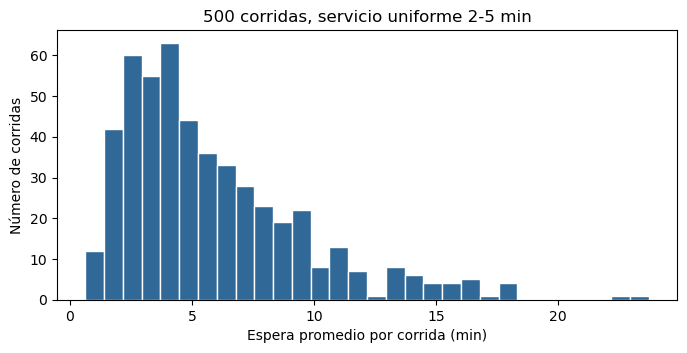

In [15]:
def correr(rng, p, servicio=None, n_corridas=500):
    filas = []
    for _ in range(n_corridas):
        llegadas = np.cumsum(rng.exponential(scale=p["media_llegadas"], size=p["n_clientes"]))
        if servicio is None:
            servicios = rng.uniform(p["serv_min"], p["serv_max"], size=p["n_clientes"])
        else:
            servicios = servicio(rng, p["n_clientes"])
        tabla, cont = simular_corrida(llegadas, servicios)
        filas.append(medir(llegadas, servicios, cont))
    return pd.DataFrame(filas)

rng = np.random.default_rng(2026)
df = correr(rng, parametros)

n_corr = len(df)
resumen = pd.DataFrame({"media": df.mean(), "margen": 2 * df.std() / np.sqrt(n_corr)})
display(resumen.round(3))
print(f"Mediana de la espera promedio: {df['espera_prom'].median():.3f}  |  media: {df['espera_prom'].mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["espera_prom"], bins=30, color="#306998", edgecolor="white")
ax.set_xlabel("Espera promedio por corrida (min)")
ax.set_ylabel("Número de corridas")
ax.set_title("500 corridas, servicio uniforme 2-5 min")
plt.show()

**Respuesta:** El histograma tiene cola larga hacia la derecha: la mayoría de las corridas tienen esperas pequeñas, pero algunas con rachas de llegadas seguidas producen esperas muy altas. Esos valores extremos jalan la media hacia arriba (5.83) y no afectan tanto a la mediana (4.79), por eso la mediana es menor.

## Ejercicio 4. Comparación de escenarios

Uniforme 2-5        Exponencial 3.5       
                   media margen           media margen
espera_prom        5.832  0.337           8.566  0.599
espera_max        15.256  0.598          23.005  1.036
ocupacion          0.808  0.009           0.772  0.012

Uniforme: espera promedio entre 5.495 y 6.169
Exponencial: espera promedio entre 7.967 y 9.166


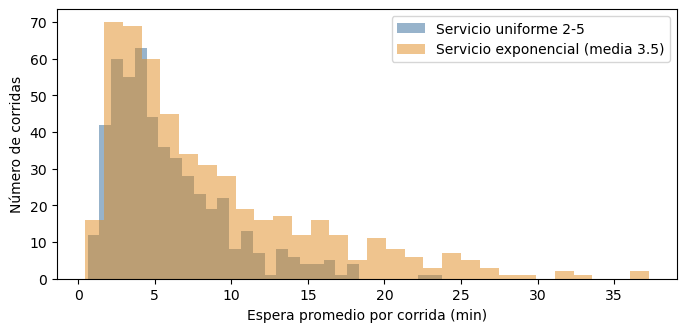

In [17]:
df_unif = correr(np.random.default_rng(2026), parametros)
df_expo = correr(np.random.default_rng(2026), parametros,
                 servicio=lambda rng, n: rng.exponential(scale=3.5, size=n))

def resumir(d):
    return pd.DataFrame({"media": d.mean(), "margen": 2 * d.std() / np.sqrt(len(d))})

tabla_comp = pd.concat({"Uniforme 2-5": resumir(df_unif), "Exponencial 3.5": resumir(df_expo)}, axis=1)
display(tabla_comp.round(3))

for nombre, d in [("Uniforme", df_unif), ("Exponencial", df_expo)]:
    m = d["espera_prom"].mean(); e = 2 * d["espera_prom"].std() / np.sqrt(len(d))
    print(f"{nombre}: espera promedio entre {m - e:.3f} y {m + e:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df_unif["espera_prom"], bins=30, alpha=0.5, label="Servicio uniforme 2-5", color="#306998")
ax.hist(df_expo["espera_prom"], bins=30, alpha=0.5, label="Servicio exponencial (media 3.5)", color="#e08a1e")
ax.set_xlabel("Espera promedio por corrida (min)")
ax.set_ylabel("Número de corridas")
ax.legend()
plt.show()

**Respuesta:** No se enciman: la espera promedio con servicio uniforme está entre 5.50 y 6.17 min y con servicio exponencial entre 7.97 y 9.17 min, así que el límite superior del primero queda por debajo del inferior del segundo. La diferencia (unos 2.7 min) es mucho mayor que los márgenes de error (0.34 y 0.60), por lo que sí es real. Con el mismo promedio de servicio, la exponencial tiene más variabilidad (algunos servicios muy largos), y eso alarga las filas.

## Ejercicio 5. La fila como nivel continuo

dt = 1:
  nivel en el minuto 10: 2.00
  nivel en el minuto 20: 0.00
  la fila se vacía en el minuto 17
dt = 0.1: la fila se vacía en el minuto 16.7
Sin max(0, ...) el nivel en el minuto 20 sería -1.00


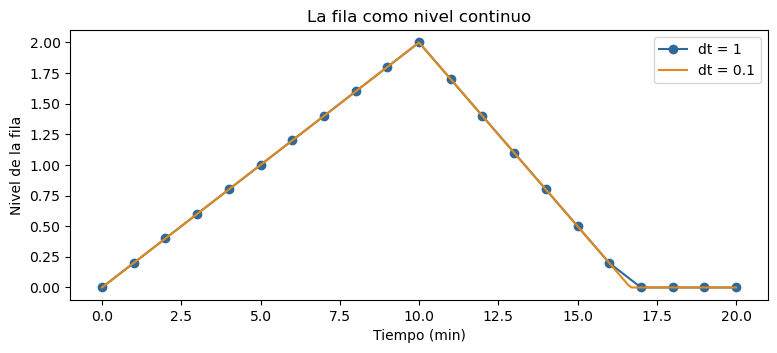

In [19]:
def modelo_continuo(dt, sin_max=False):
    pasos = int(round(20 / dt))
    corte = int(round(10 / dt))          # paso en que cambian las tasas (minuto 10)
    nivel = 0.0
    filas = [(0.0, 0.0)]
    for i in range(pasos):
        entra, sale = (0.5, 0.3) if i < corte else (0.2, 0.5)
        if sin_max:
            nivel = nivel + (entra - sale) * dt
        else:
            nivel = max(0, nivel + (entra - sale) * dt)
        filas.append((round((i + 1) * dt, 4), nivel))
    return pd.DataFrame(filas, columns=["minuto", "nivel"])

def minuto_vacia(d):
    despues = d[(d["minuto"] > 10) & (d["nivel"] <= 1e-9)]
    return despues["minuto"].iloc[0]

d1 = modelo_continuo(1)
print("dt = 1:")
print(f"  nivel en el minuto 10: {d1.loc[d1.minuto == 10, 'nivel'].iloc[0]:.2f}")
print(f"  nivel en el minuto 20: {d1.loc[d1.minuto == 20, 'nivel'].iloc[0]:.2f}")
print(f"  la fila se vacía en el minuto {minuto_vacia(d1):g}")

d01 = modelo_continuo(0.1)
print(f"dt = 0.1: la fila se vacía en el minuto {minuto_vacia(d01):g}")

d_sin = modelo_continuo(1, sin_max=True)
print(f"Sin max(0, ...) el nivel en el minuto 20 sería {d_sin.loc[d_sin.minuto == 20, 'nivel'].iloc[0]:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(d1["minuto"], d1["nivel"], marker="o", label="dt = 1", color="#306998")
ax.plot(d01["minuto"], d01["nivel"], label="dt = 0.1", color="#e08a1e")
ax.set_xlabel("Tiempo (min)")
ax.set_ylabel("Nivel de la fila")
ax.set_title("La fila como nivel continuo")
ax.legend()
plt.show()

**Cambio con dt = 0.1:** Con `dt = 1` la fila se vacía en el minuto 17 y con `dt = 0.1` en el 16.7. El valor exacto es 10 + 2/0.3 = 16.67; con pasos de 1 minuto solo se puede detectar al final del paso en que el nivel llega a cero, y con pasos más finos se acerca más al valor real.

**Sin `max(0, ...)`:** el nivel seguiría bajando después de vaciarse y llegaría a -1.0 en el minuto 20, es decir, una fila con clientes negativos, lo cual no tiene sentido físico. Una fila vacía no puede tener menos de cero clientes: cuando no hay quien atender, la ventanilla simplemente queda ociosa.

## Ejercicio 6. ¿Discreto o continuo?

1. **Nivel de agua de una presa: continuo.** El agua entra y sale todo el tiempo de forma gradual (lluvia, escurrimientos, extracción) y no se cuenta por unidades, así que el nivel cambia poco a poco.
2. **Fila de un cajero automático: eventos discretos.** El sistema solo cambia cuando llega o sale una persona, y los clientes se pueden contar uno por uno.
3. **Gasolina en el tanque de una estación de servicio: continuo.** La gasolina es un fluido que baja gradualmente conforme se despacha y sube cuando llega la pipa; se mide en litros, no en unidades contables. (Si el interés fuera contar los camiones que llegan a surtir, sería discreto.)
4. **Autos dentro de un estacionamiento: eventos discretos.** Los autos son unidades contables y el número solo cambia cuando uno entra o sale.
5. **Agua de un tinaco: continuo.** El nivel sube al llenarse y baja con el consumo de forma gradual; es una cantidad de fluido, no algo que se cuente por unidades.